In [1]:
!pip install mne

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 26.9 MB/s eta 0:00:00


In [2]:
#Import necessary Librry
import os
import time
import numpy as np
import pandas as pd

import numpy as np
from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, classification_report, accuracy_score
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
import joblib

import mne

import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from keras.regularizers import l2
from keras import backend as K
from tensorflow.keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D, Dropout,\
 Flatten, Dense, Reshape, LSTM,  SimpleRNN, GRU, Bidirectional, Activation

from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten,\
 BatchNormalization,  DepthwiseConv2D, AveragePooling2D, SeparableConv2D

from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model
#from wandb.integration.keras import WandbCallback
import warnings
warnings.filterwarnings('ignore')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
for dirname, _, filenames in os.walk('/content/drive/MyDrive/EEG_80'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/content/drive/MyDrive/EEG_80/1.csv
/content/drive/MyDrive/EEG_80/10.csv
/content/drive/MyDrive/EEG_80/11.csv
/content/drive/MyDrive/EEG_80/12.csv
/content/drive/MyDrive/EEG_80/13.csv
/content/drive/MyDrive/EEG_80/14.csv
/content/drive/MyDrive/EEG_80/15.csv
/content/drive/MyDrive/EEG_80/16.csv
/content/drive/MyDrive/EEG_80/17.csv
/content/drive/MyDrive/EEG_80/18.csv
/content/drive/MyDrive/EEG_80/19.csv
/content/drive/MyDrive/EEG_80/2.csv
/content/drive/MyDrive/EEG_80/20.csv
/content/drive/MyDrive/EEG_80/21.csv
/content/drive/MyDrive/EEG_80/22.csv
/content/drive/MyDrive/EEG_80/23.csv
/content/drive/MyDrive/EEG_80/24.csv
/content/drive/MyDrive/EEG_80/3.csv
/content/drive/MyDrive/EEG_80/4.csv
/content/drive/MyDrive/EEG_80/5.csv
/content/drive/MyDrive/EEG_80/6.csv
/content/drive/MyDrive/EEG_80/66.csv
/content/drive/MyDrive/EEG_80/67.csv
/content/drive/MyDrive/EEG_80/68.csv
/content/drive/MyDrive/EEG_80/69.csv
/content/drive/MyDrive/EEG_80/7.csv
/content/drive/MyDrive/EEG_80/70.csv
/content

In [5]:
column_list = pd.read_csv("/content/drive/MyDrive/EEG_80/columnLabels.csv").columns
electrode = pd.read_csv("/content/drive/MyDrive/EEG_80/columnLabels.csv").columns[4:]

In [6]:
column_list

Index(['subject', 'trial', 'condition', 'sample', 'Fp1', 'AF7', 'AF3', 'F1',
       'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7',
       'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3',
       'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4', 'AFz',
       'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz',
       'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6',
       'P8', 'P10', 'PO8', 'PO4', 'O2', 'VEOa', 'VEOb', 'HEOL', 'HEOR', 'Nose',
       'TP10'],
      dtype='object')

In [7]:
demographic = pd.read_csv("/content/drive/MyDrive/EEG_80/demographic.csv")

In [8]:
for i, t in enumerate(list(demographic[" group"])):
  demographic["Patient"] = np.where(demographic[" group"] == 0, "Healthy","Schizoprnia")
  demographic["Patient"] = np.where(demographic[" group"] == 1, "Schizoprnia", "Helathy")

In [9]:
demographic

,subject,group,gender,age,education,Patient
0,1,0,M,44,16.0,Helathy
1,2,0,M,39,17.0,Helathy
2,3,0,M,53,18.0,Helathy
3,4,0,M,52,15.0,Helathy
4,5,0,M,41,16.0,Helathy
...,...,...,...,...,...,...
76,77,1,M,28,13.0,Schizoprnia
77,78,1,F,32,16.0,Schizoprnia
78,79,1,M,37,16.0,Schizoprnia
79,80,1,M,33,13.0,Schizoprnia


In [10]:
count = demographic.groupby(["Patient"], as_index = False)["subject"].count()
count

,Patient,subject
0,Helathy,32
1,Schizoprnia,49


In [11]:
# dict for data preprocessing
dict_ = dict(zip(demographic["subject"], demographic[" group"]))

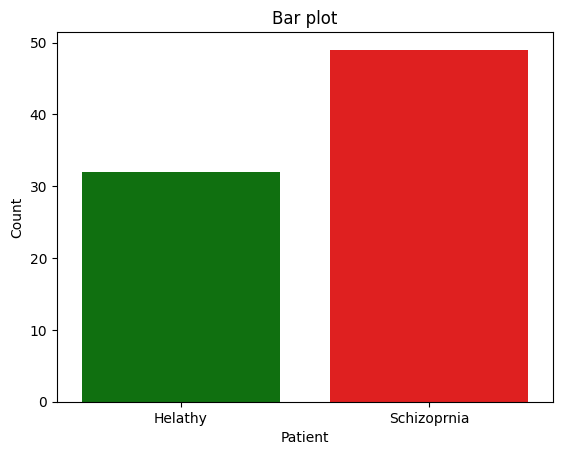

In [ ]:
sns.barplot(x = "Patient", y = "subject", data = count, palette = ["green", "red"])
plt.ylabel("Count")
plt.title("Bar plot")
plt.show()

In [ ]:
time = pd.read_csv("/content/drive/MyDrive/EEG_80/time.csv")
time.head()

,sample,time_ms
0,1,-1500.0000
1,2,-1499.0234
2,3,-1498.0469
3,4,-1497.0703
4,5,-1496.0938


## Schizoprenic and Healthy

In [ ]:
csv_10 = pd.read_csv("/content/drive/MyDrive/EEG_80/10.csv", header=None, names=column_list)
csv_10.head()

,subject,trial,condition,sample,Fp1,AF7,AF3,F1,F3,F5,...,P10,PO8,PO4,O2,VEOa,VEOb,HEOL,HEOR,Nose,TP10
0,10.0,100.0,1.0,1.0,-22.8774,-78.6755,-8.0013,-12.4386,-23.6352,-31.3560,...,43.4493,3.1654,-9.1876,-12.9141,43.3718,-20.7366,5.3274,-28.0435,0.2110,18.6603
1,10.0,100.0,1.0,2.0,-20.1172,-75.1138,-5.9297,-11.1830,-22.1853,-32.4027,...,46.7718,6.1241,-7.2565,-10.6454,43.5867,-17.1981,3.8222,-29.4389,3.7093,17.4339
2,10.0,100.0,1.0,3.0,-20.2351,-75.2874,-5.5513,-9.8152,-20.5348,-32.0249,...,48.5472,4.2711,-8.6834,-10.7720,44.6609,-16.5503,2.3639,-30.5062,2.3482,16.2232
3,10.0,100.0,1.0,4.0,-22.7280,-79.1659,-6.9681,-10.3275,-20.4670,-31.7483,...,50.6465,4.0239,-9.5835,-10.9540,42.1414,-25.9337,-1.4694,-31.8234,-0.5128,15.6688
4,10.0,100.0,1.0,5.0,-27.0743,-84.2088,-10.9203,-13.9038,-23.2044,-33.9135,...,53.4349,3.7302,-11.2227,-12.3021,39.6062,-31.6765,-3.4746,-33.7189,-6.0457,14.3174


In [ ]:
csv_37 = pd.read_csv("/content/drive/MyDrive/EEG_80/37.csv", header=None, names=column_list)
csv_37.head()

,subject,trial,condition,sample,Fp1,AF7,AF3,F1,F3,F5,...,P10,PO8,PO4,O2,VEOa,VEOb,HEOL,HEOR,Nose,TP10
0,37.0,100.0,1.0,1.0,1.1681,37.4027,-40.6399,-27.4674,-60.8957,-94.6145,...,46.1222,-4.1993,-110.4118,37.1749,83.1480,-19.4276,66.5672,46.1873,2.5932,96.7349
1,37.0,100.0,1.0,2.0,-1.6434,34.9030,-43.2394,-29.7139,-63.3286,-96.7482,...,45.8155,-6.9276,-112.7922,34.9177,77.3229,-15.9337,74.6886,46.7635,3.4713,103.1887
2,37.0,100.0,1.0,3.0,-2.9714,32.3400,-43.6542,-31.6725,-64.7148,-97.2714,...,42.9153,-7.1382,-112.8195,34.4698,64.4041,-13.9710,79.4663,49.9959,5.7244,105.5799
3,37.0,100.0,1.0,4.0,-3.0366,30.6723,-42.6233,-31.1452,-64.2292,-96.8728,...,40.4598,-5.9076,-111.2138,35.4907,53.7041,-11.7584,80.2126,55.4470,8.3212,100.1587
4,37.0,100.0,1.0,5.0,-5.1264,28.1461,-44.0419,-32.3592,-66.0499,-99.2053,...,39.7443,-6.0253,-111.1703,35.9560,55.2384,-9.4989,78.7872,59.9451,14.3712,94.4719


## Both dataset demographic details

In [ ]:
demographic[ demographic["subject"] == 10]  #healthy

,subject,group,gender,age,education,Patient
9,10,0,M,53,19.0,Helathy


In [ ]:
demographic[ demographic["subject"] == 37] #Schizoprenia

,subject,group,gender,age,education,Patient
36,37,1,M,53,13.0,Schizoprnia


## Check Non Value

In [ ]:
csv_10.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 903168 entries, 0 to 903167
Data columns (total 74 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   subject    903168 non-null  float64
 1   trial      903168 non-null  float64
 2   condition  903168 non-null  float64
 3   sample     903168 non-null  float64
 4   Fp1        903168 non-null  float64
 5   AF7        903168 non-null  float64
 6   AF3        903168 non-null  float64
 7   F1         903168 non-null  float64
 8   F3         903168 non-null  float64
 9   F5         903168 non-null  float64
 10  F7         903168 non-null  float64
 11  FT7        903168 non-null  float64
 12  FC5        903168 non-null  float64
 13  FC3        903168 non-null  float64
 14  FC1        903168 non-null  float64
 15  C1         903168 non-null  float64
 16  C3         903168 non-null  float64
 17  C5         903168 non-null  float64
 18  T7         903168 non-null  float64
 19  TP7        903168 non-n

In [ ]:
csv_37.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 890880 entries, 0 to 890879
Data columns (total 74 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   subject    890880 non-null  float64
 1   trial      890880 non-null  float64
 2   condition  890880 non-null  float64
 3   sample     890880 non-null  float64
 4   Fp1        890880 non-null  float64
 5   AF7        890880 non-null  float64
 6   AF3        890880 non-null  float64
 7   F1         890880 non-null  float64
 8   F3         890880 non-null  float64
 9   F5         890880 non-null  float64
 10  F7         890880 non-null  float64
 11  FT7        890880 non-null  float64
 12  FC5        890880 non-null  float64
 13  FC3        890880 non-null  float64
 14  FC1        890880 non-null  float64
 15  C1         890880 non-null  float64
 16  C3         890880 non-null  float64
 17  C5         890880 non-null  float64
 18  T7         890880 non-null  float64
 19  TP7        890880 non-n

## Shape of those datset

In [ ]:
csv_10.shape

(903168, 74)

In [ ]:
csv_37.shape

(890880, 74)

## See descriptive statistics

In [ ]:
csv_10.describe() #Healthy

,subject,trial,condition,sample,Fp1,AF7,AF3,F1,F3,F5,...,P10,PO8,PO4,O2,VEOa,VEOb,HEOL,HEOR,Nose,TP10
count,903168.0,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,...,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000,903168.000000
mean,10.0,50.670068,2.003401,1536.500000,3.038784,2.557580,2.768087,2.365992,1.531788,1.328728,...,1.056763,1.308568,1.324111,0.822417,28.577227,-5.780616,3.094929,9.576918,-1.961261,3.589513
std,0.0,28.548280,0.822715,886.810457,51.237065,52.752413,53.271078,50.980171,42.255198,47.982284,...,39.233368,25.086144,18.546366,22.883909,163.010620,78.956308,73.902817,52.269255,77.084253,26.259103
min,10.0,1.000000,1.000000,1.000000,-424.300900,-528.644300,-484.951500,-520.677300,-407.763500,-458.679400,...,-505.043200,-231.782000,-113.497400,-145.660500,-988.492600,-618.715100,-473.197200,-292.353600,-831.549300,-132.883700
25%,10.0,26.000000,1.000000,768.750000,-18.276325,-18.155525,-17.692400,-15.564100,-13.837525,-13.963000,...,-10.454800,-9.358200,-8.647825,-10.181425,-22.246700,-27.629350,-17.388125,-10.972725,-16.228025,-10.034125
50%,10.0,51.000000,2.000000,1536.500000,2.821200,2.172150,2.844850,2.256700,1.664150,1.335250,...,0.843900,0.739750,1.175350,0.469550,5.372000,-1.898600,2.053800,3.678650,-1.298650,2.864900
75%,10.0,75.000000,3.000000,2304.250000,23.954025,22.673600,23.210650,19.844550,17.318125,16.140425,...,11.929300,10.871300,10.968100,10.991125,56.993350,17.806875,24.794100,25.570900,11.648025,16.666925
max,10.0,100.000000,3.000000,3072.000000,444.278700,467.079100,499.295600,537.195800,409.397400,464.443200,...,438.445500,274.736800,126.397300,168.488700,1385.143100,707.793100,558.073100,355.929600,850.171600,221.088000


In [ ]:
csv_37.describe() #Schizoprenia

,subject,trial,condition,sample,Fp1,AF7,AF3,F1,F3,F5,...,P10,PO8,PO4,O2,VEOa,VEOb,HEOL,HEOR,Nose,TP10
count,890880.0,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,...,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000,890880.000000
mean,37.0,50.006897,2.013793,1536.500000,2.589184,2.301261,1.516421,0.486347,1.307449,0.998781,...,0.507303,0.776089,-0.209058,-0.619397,8.287967,-3.649211,0.008991,1.206717,-2.277284,-0.070671
std,0.0,28.733871,0.813560,886.810464,39.063635,32.435068,44.780669,20.820523,47.825575,44.741357,...,26.703878,27.152362,24.732113,28.891287,78.229971,39.449884,26.125861,25.486341,27.276079,44.977510
min,37.0,1.000000,1.000000,1.000000,-399.356800,-449.599500,-333.960100,-211.759200,-380.425000,-280.132800,...,-370.814300,-300.338800,-253.785400,-258.349300,-416.384900,-295.823300,-292.441600,-284.925600,-341.341400,-405.802900
25%,37.0,25.000000,1.000000,768.750000,-11.818725,-9.062725,-14.241875,-8.366050,-13.450125,-13.908800,...,-9.039600,-9.392300,-10.414925,-11.869825,-24.491800,-18.432025,-11.452525,-11.875900,-12.987100,-10.744625
50%,37.0,50.000000,2.000000,1536.500000,1.123650,1.223200,0.706850,0.569850,0.352450,0.399550,...,0.566650,0.792250,0.242200,0.073750,3.620350,-1.222200,0.427800,0.652200,-1.005200,-0.070800
75%,37.0,75.000000,3.000000,2304.250000,15.244850,12.625125,15.945775,9.846900,14.536250,14.742200,...,10.299125,11.634400,10.819025,11.745825,34.956450,12.985900,12.253725,13.858850,9.809325,10.919725
max,37.0,100.000000,3.000000,3072.000000,390.349700,414.352800,297.781800,183.117600,474.248400,328.710000,...,220.985900,372.672300,190.791000,237.684000,368.846300,222.078100,310.113600,188.503900,264.465400,1499.107200


## Total trail unique value

In [ ]:
csv_10.trial.nunique() #Healthy

100

In [ ]:
csv_37.trial.nunique() #Schizoprenia

100

## Trail groupby sample count

In [ ]:
count_10 = csv_10.groupby("trial").count()                     #Healthy
print("Total number of trail :" ,count_10.shape[0])
print(count_10.head())

Total number of trail : 100
       subject  condition  sample   Fp1   AF7   AF3    F1    F3    F5    F7  \
trial                                                                         
1.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
2.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
3.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
4.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
5.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   

       ...   P10   PO8   PO4    O2  VEOa  VEOb  HEOL  HEOR  Nose  TP10  
trial  ...                                                              
1.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
2.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
3.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
4.0    ...  9216  9216  9216  9216  9216  9216  9216 

In [ ]:
count_9216_f0r_10 = count_10[count_10["subject"]== 9216]    #Healthy
print("Total number of train with contain each trail 9216 temporal sample is :", count_9216_f0r_10.shape[0])

Total number of train with contain each trail 9216 temporal sample is : 94


In [ ]:
count_37 = csv_37.groupby("trial").count()                 #Schizoprenia
print("Total number of trail :" ,count_37.shape[0])
print(count_37.head())

Total number of trail : 100
       subject  condition  sample   Fp1   AF7   AF3    F1    F3    F5    F7  \
trial                                                                         
1.0       6144       6144    6144  6144  6144  6144  6144  6144  6144  6144   
2.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
3.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
4.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   
5.0       9216       9216    9216  9216  9216  9216  9216  9216  9216  9216   

       ...   P10   PO8   PO4    O2  VEOa  VEOb  HEOL  HEOR  Nose  TP10  
trial  ...                                                              
1.0    ...  6144  6144  6144  6144  6144  6144  6144  6144  6144  6144  
2.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
3.0    ...  9216  9216  9216  9216  9216  9216  9216  9216  9216  9216  
4.0    ...  9216  9216  9216  9216  9216  9216  9216 

In [ ]:
count_9216_for_37 = count_37[count_37["subject"]== 9216]    #Healthy
print("Total number of train with contain each trail 9216 temporal sample is :", count_9216_for_37.shape[0])

Total number of train with contain each trail 9216 temporal sample is : 90


## Schizoprenia and helathy by Age 53

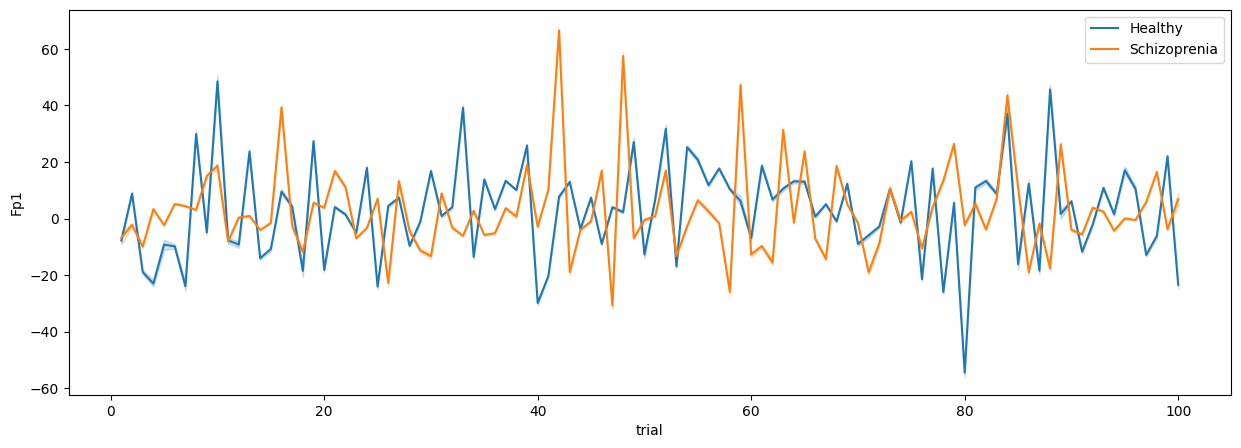

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "Fp1", data = csv_10, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "Fp1", data = csv_37, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

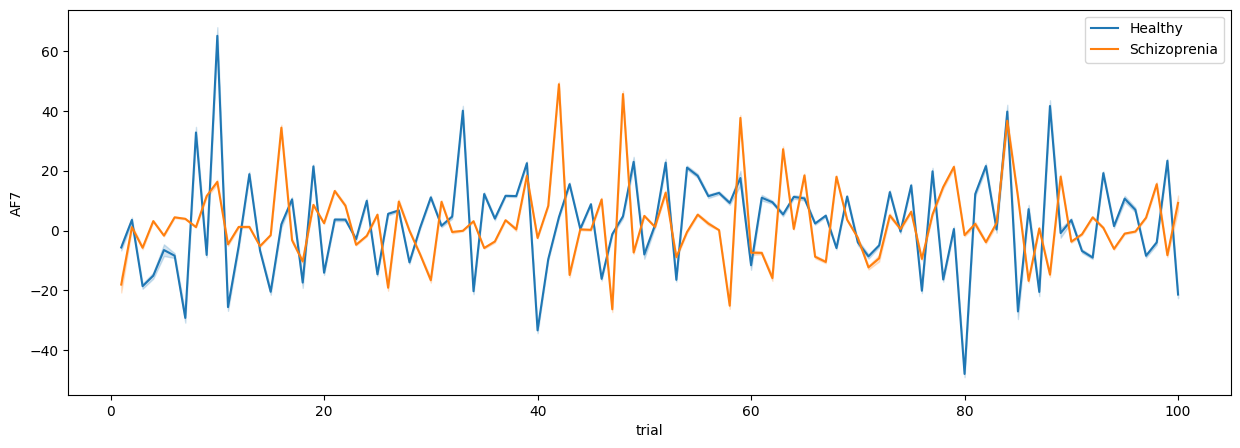

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "AF7", data = csv_10, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "AF7", data = csv_37, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

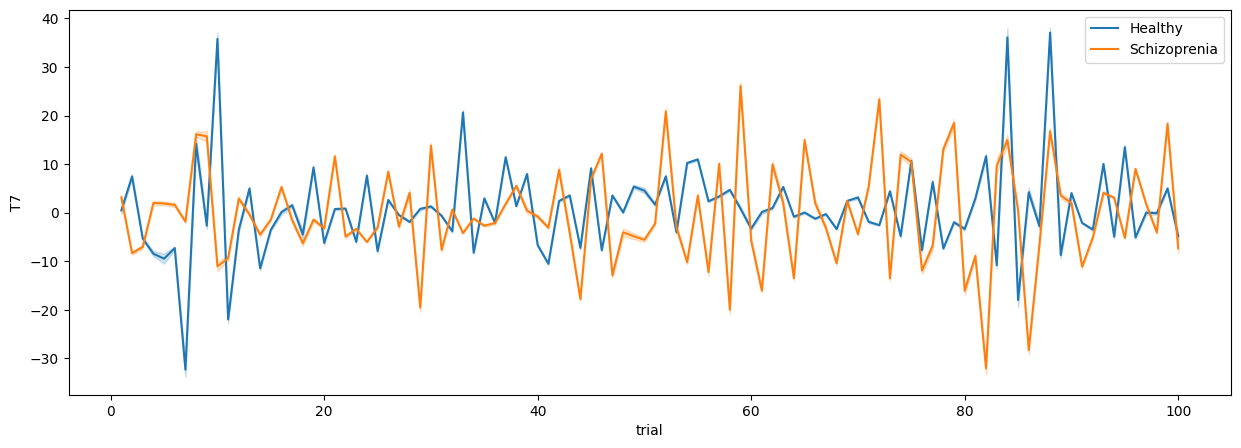

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "T7", data = csv_10, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "T7", data = csv_37, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

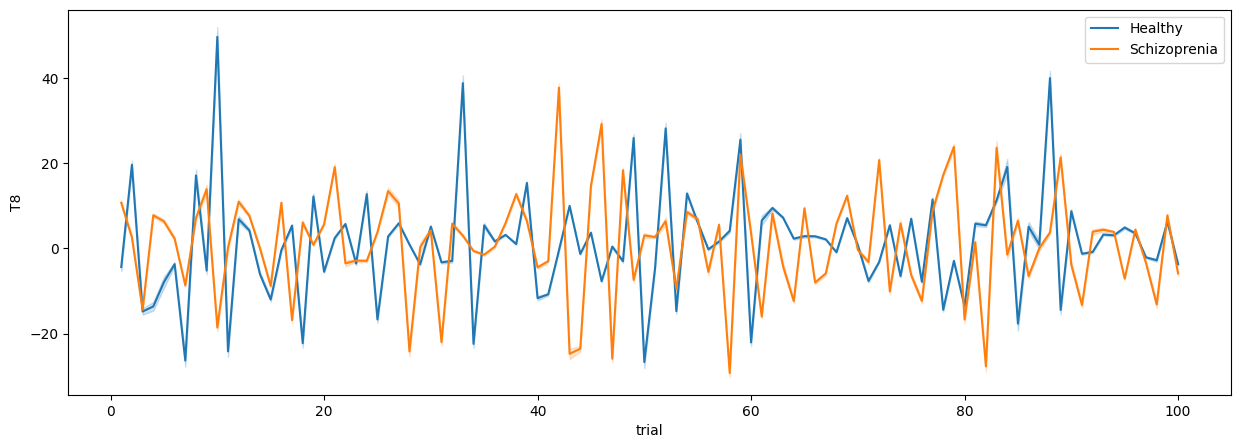

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "T8", data = csv_10, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "T8", data = csv_37, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

## Age 44

In [ ]:
csv_1 = pd.read_csv("/content/drive/MyDrive/EEG_80/1.csv", header=None, names=column_list)
csv_25 = pd.read_csv("/content/drive/MyDrive/EEG_80/25.csv", header=None, names=column_list)

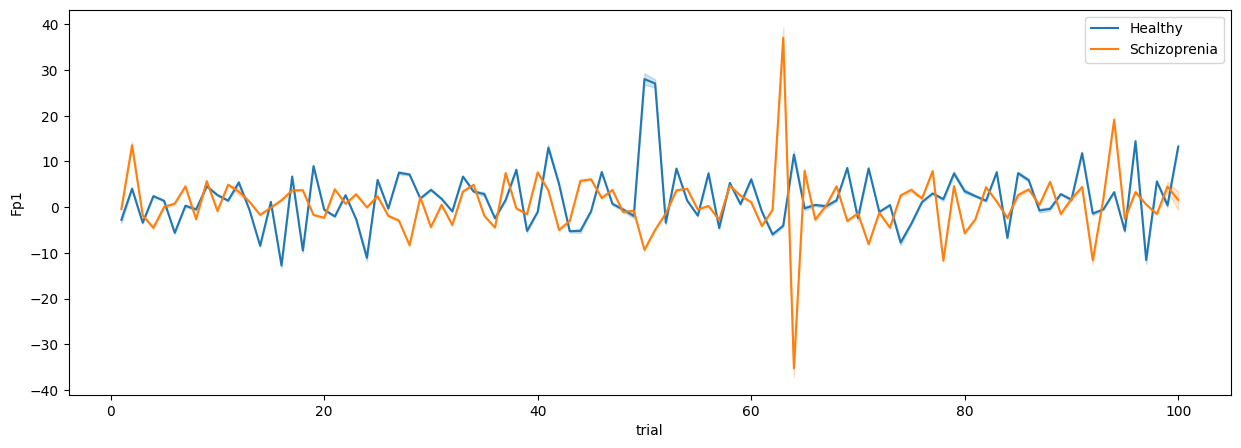

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "Fp1", data = csv_1, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "Fp1", data = csv_25, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

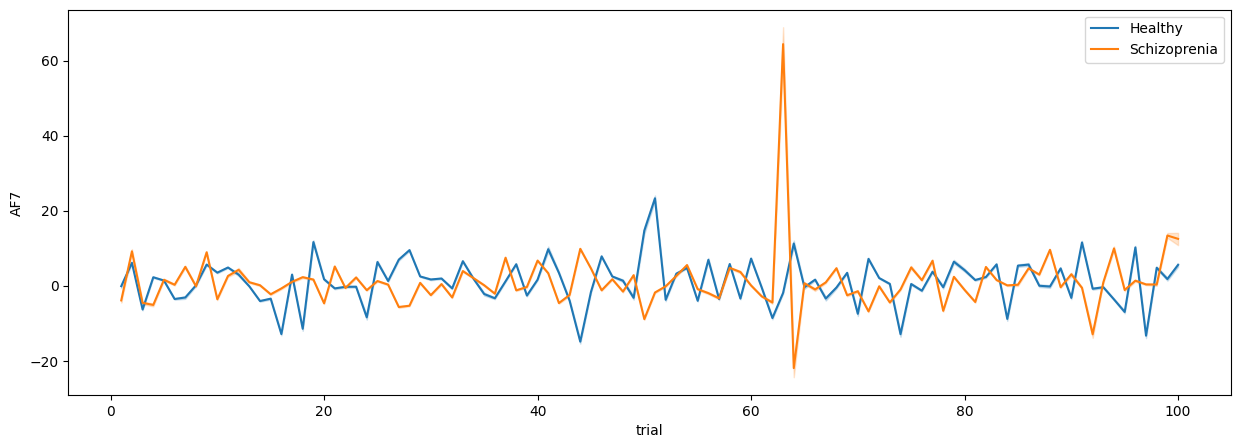

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "AF7", data = csv_1, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "AF7", data = csv_25, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

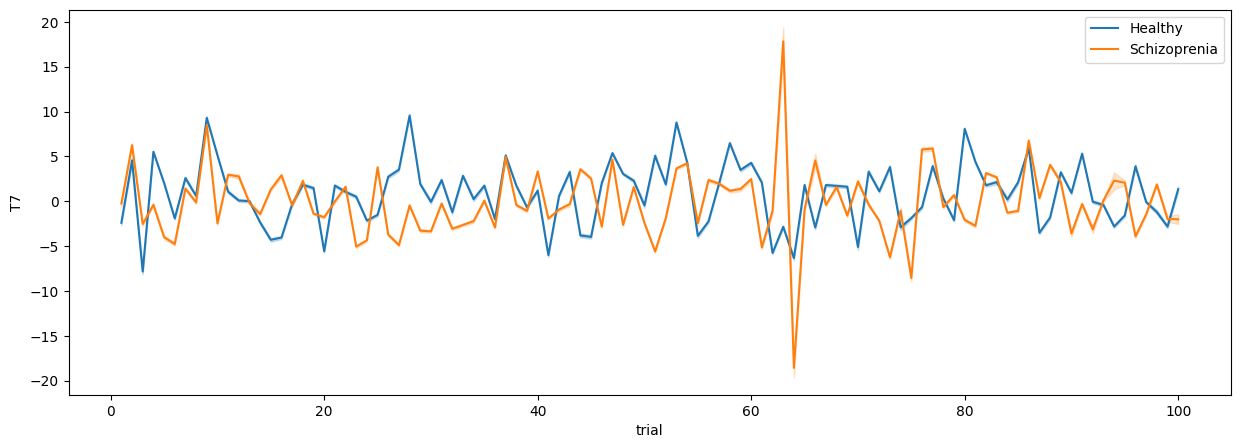

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "T7", data = csv_1, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "T7", data = csv_25, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

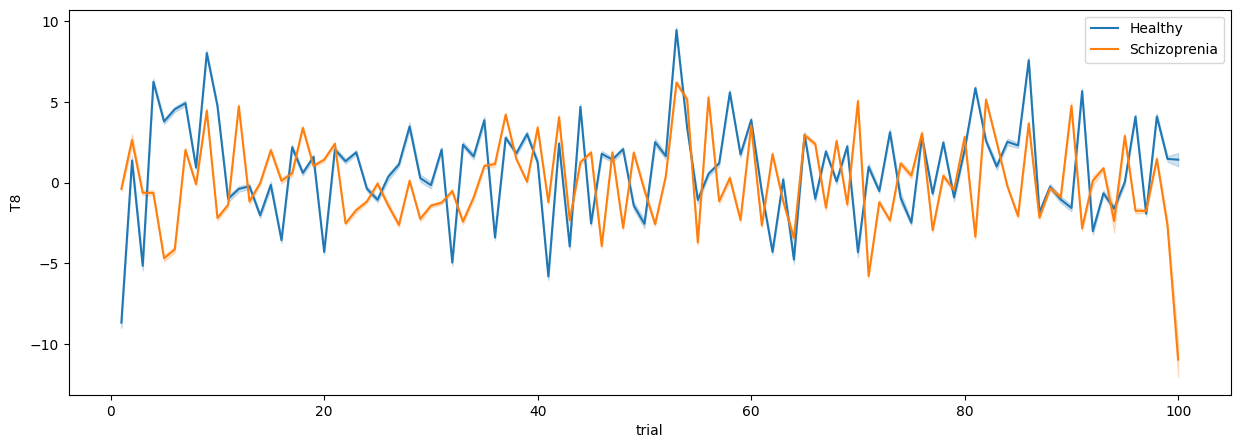

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(15,5))
sns.lineplot(x = "trial", y = "T8", data = csv_1, ax = ax, label = "Healthy")
sns.lineplot(x = "trial", y = "T8", data = csv_25, ax = ax, label = "Schizoprenia")
plt.legend()
plt.show()

## Plot for all electrodes

In [ ]:
csv_10_elec = csv_10.iloc[:, 3:]
csv_37_elec = csv_37.iloc[:, 3:]

In [ ]:
time_csv_10 = csv_10_elec.merge(time, on = 'sample', how = "left")
time_csv_37 = csv_37_elec.merge(time, on = 'sample', how = "left")

In [ ]:
data = time_csv_10.T.values
raw_10 = mne.io.RawArray(data, info = mne.create_info(ch_names = list(time_csv_10.columns), sfreq = 256, ch_types = "eeg"))

Creating RawArray with float64 data, n_channels=72, n_times=903168
    Range : 0 ... 903167 =      0.000 ...  3527.996 secs
Ready.


Using matplotlib as 2D backend.


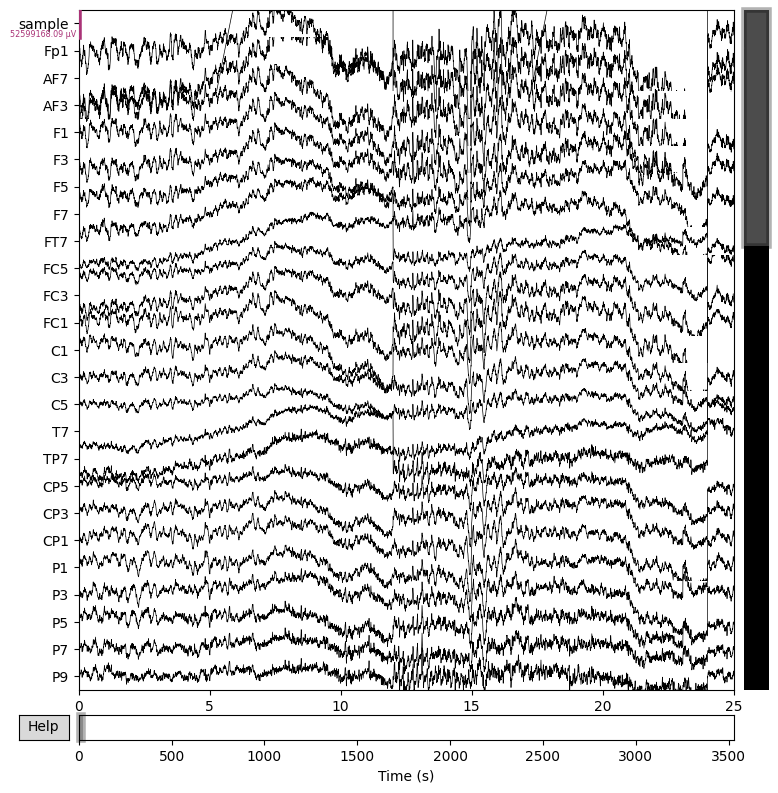

In [ ]:
mne_10 = raw_10.plot(n_channels = 25, duration = 25, scalings = "auto", show = True )
plt.show()
mne_10.savefig("mne_10.jpg")

In [ ]:
data = time_csv_37.T.values
raw_37 = mne.io.RawArray(data, info = mne.create_info(ch_names = list(time_csv_37.columns), sfreq = 256, ch_types = "eeg"))

Creating RawArray with float64 data, n_channels=72, n_times=890880
    Range : 0 ... 890879 =      0.000 ...  3479.996 secs
Ready.


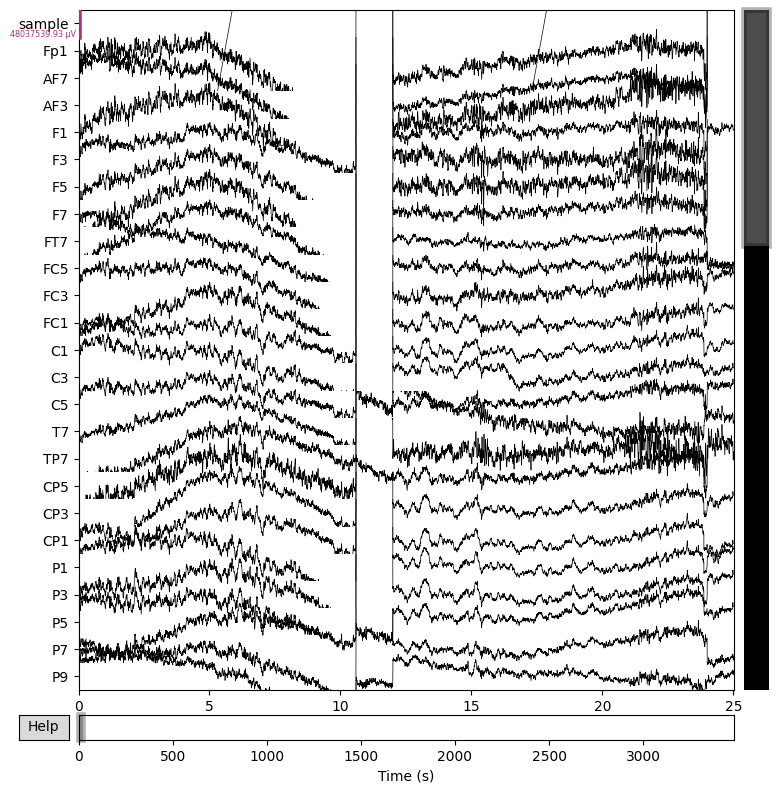

In [ ]:
mne_37 = raw_37.plot(n_channels = 25, duration = 25, scalings = "auto", show = True )
plt.show()
mne_37.savefig("mne_37.jpg")

### Data Processing for model

In [12]:
def average(m, n):
    shape = m.shape
    assert len(shape) == 2
    assert shape[0] % n == 0
    a = m.reshape(shape[0] // n, n,
                  shape[1])
    mean_vector = a.mean(axis=1)
    return mean_vector

In [13]:
n = 16
x_count = 0
X = np.zeros((81 * 100,  9216 * len(electrode) // n), dtype="float32")
Y = np.zeros(len(X))

part1_path = "/content/drive/MyDrive/EEG_80"



column_list = pd.read_csv("/content/drive/MyDrive/EEG_80/columnLabels.csv").columns
for person_num in tqdm(range(1, 82)):


    csv_path = f"{part1_path}/{person_num}.csv"

    df = pd.read_csv(csv_path,
                header=None,
                names=column_list)
    trial_list = set(df.trial)


    for t1, trial_number in enumerate(trial_list):
        trials = len(df[df.trial == trial_number])
        if trials == 9216.0:
            matrix = df[df.trial == trial_number][electrode].values
            averaged = average(matrix, n = n)
            averaged_N = averaged.reshape(-1)
            X[x_count] = averaged_N.astype(np.float32)
            Y[x_count] = dict_[person_num]
            x_count += 1

X = X[: x_count]
Y = Y[: x_count]
print("Total trials for X - ", x_count)
print("Total trials for Y- ", x_count)

  0%|          | 0/81 [00:00<?, ?it/s]

Total trials for X -  7092
Total trials for Y-  7092


In [14]:
#Normalization

X_norm = (normalize(X.reshape(-1, 70), axis=0, norm='max')).reshape(X.shape)
X_norm.shape

(7092, 40320)

In [15]:
#Train test split
X_train, X_test, Y_train, Y_test = train_test_split(X_norm, Y, test_size=0.2, shuffle=True, random_state=42)

### CNN

In [16]:
X_train_1d = X_train.reshape(-1, 576, 70)
X_test_1d = X_test.reshape(-1, 576, 70)

In [ ]:
model1d = Sequential()


model1d.add(Conv1D(filters=64, kernel_size=5, activation='elu', input_shape=(576, 70)))
model1d.add(BatchNormalization())
model1d.add(MaxPooling1D(pool_size=2))
model1d.add(Dropout(0.3))


model1d.add(Conv1D(filters=128, kernel_size=3, activation='elu'))
model1d.add(BatchNormalization())
model1d.add(MaxPooling1D(pool_size=2))
model1d.add(Dropout(0.4))


model1d.add(Conv1D(filters=256, kernel_size=3, activation='elu'))
model1d.add(BatchNormalization())
model1d.add(MaxPooling1D(pool_size=2))
model1d.add(Dropout(0.4))

model1d.add(Flatten())

model1d.add(Dense(128, activation='elu'))
model1d.add(Dropout(0.3))
model1d.add(Dense(1, activation='sigmoid'))

In [ ]:
model1d.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model1d.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)                    │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_6 (MaxPooling1D)       │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_7 (Conv1D)                    │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_7 (MaxPooling1D)       │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_8 (Conv1D)                    │ (None, 140, 256)            │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_8                │ (None, 140, 256)            │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_8 (MaxPooling1D)       │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 17920)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │       2,293,888 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,441,537 (9.31 MB)

 Trainable params: 2,440,641 (9.31 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
history_1d = model1d.fit(X_train_1d, Y_train, epochs= 100, batch_size=16, validation_data=(X_test_1d, Y_test))

Epoch 1/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 22s 55ms/step - accuracy: 0.5382 - loss: 1.0745 - val_accuracy: 0.5419 - val_loss: 0.9058
Epoch 2/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.5830 - loss: 0.7051 - val_accuracy: 0.5603 - val_loss: 1.0947
Epoch 3/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.5996 - loss: 0.6751 - val_accuracy: 0.6441 - val_loss: 0.6977
Epoch 4/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 19s 54ms/step - accuracy: 0.6531 - loss: 0.6200 - val_accuracy: 0.6772 - val_loss: 0.6295
Epoch 5/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - accuracy: 0.7011 - loss: 0.5504 - val_accuracy: 0.6949 - val_loss: 0.7883
Epoch 6/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 18s 51ms/step - accuracy: 0.7319 - loss: 0.5260 - val_accuracy: 0.7252 - val_loss: 0.5771
Epoch 7/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 18s 51ms/step - accuracy: 0.7666 - loss: 0.4811 - val_accuracy: 0.6906 - val_loss: 0.6319
Epoch 8/100
355/355 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - accuracy: 0.7941 - loss: 0

In [ ]:
model1d.evaluate(X_test_1d, Y_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8276 - loss: 0.8021


[0.8394618630409241, 0.8174771070480347]

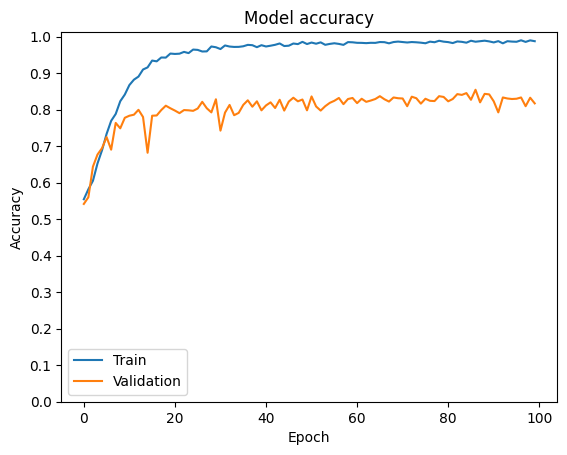

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_1d.history['accuracy'])
plt.plot(history_1d.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

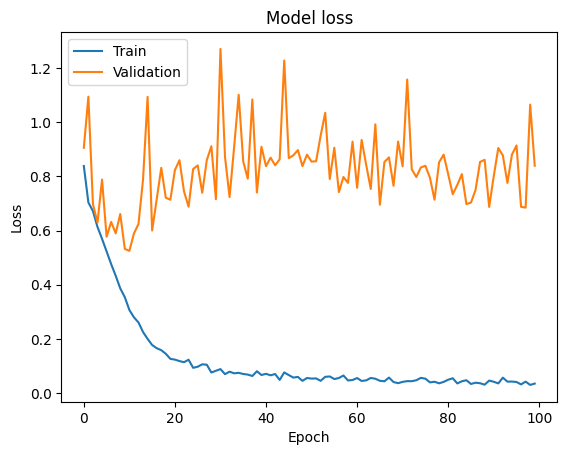

In [ ]:
# Plot training & validation loss values
plt.plot(history_1d.history['loss'])
plt.plot(history_1d.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
#Predict train
y_predict_1d_train = np.round(model1d.predict(X_train_1d))
cm_1d_train = confusion_matrix(Y_train, np.round(y_predict_1d_train))
cm_1d_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step


array([[2279,    0],
       [   0, 3394]])

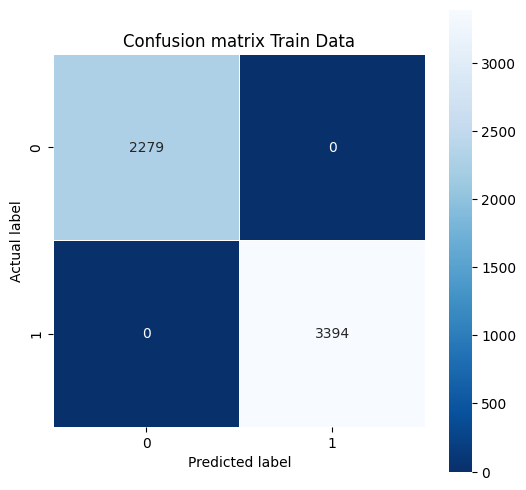

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_1d_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix Train Data')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_1d_train = classification_report(y_predict_1d_train, Y_train)
print("CNN Train Report:\n ",  report_1d_train)

CNN Train Report:
                precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2279
         1.0       1.00      1.00      1.00      3394

    accuracy                           1.00      5673
   macro avg       1.00      1.00      1.00      5673
weighted avg       1.00      1.00      1.00      5673



In [ ]:
#Predict test
y_predict_1d_test = np.round(model1d.predict(X_test_1d))
cm_1d_test = confusion_matrix(Y_test, np.round(y_predict_1d_test))
cm_1d_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


array([[466, 112],
       [147, 694]])

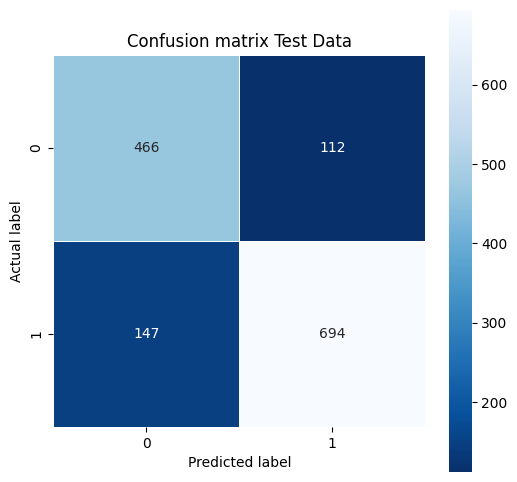

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_1d_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix Test Data')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_1d_test = classification_report(y_predict_1d_test, Y_test)
print("CNN Test Report:\n ", report_1d_test)

CNN Test Report:
                precision    recall  f1-score   support

         0.0       0.81      0.76      0.78       613
         1.0       0.83      0.86      0.84       806

    accuracy                           0.82      1419
   macro avg       0.82      0.81      0.81      1419
weighted avg       0.82      0.82      0.82      1419



In [ ]:
model1d.save('/content/drive/MyDrive/CNN_1D.keras')

### LSTM

In [ ]:
X_train_lstm = X_train.reshape(-1, 576, 70)
X_test_lstm = X_test.reshape(-1, 576, 70)

In [ ]:
model_lstm = Sequential()

model_lstm.add(LSTM(units=256, input_shape=(576, 70)))
model_lstm.add(BatchNormalization())
model_lstm.add(Dropout(0.5))


model_lstm.add(Dense(100, activation='elu'))
model_lstm.add(BatchNormalization())
model_lstm.add(Dropout(0.3))

model_lstm.add(Dense(50, activation = 'elu'))
model_lstm.add(Dropout(0.3))

model_lstm.add(Dense(1, activation='sigmoid'))

In [ ]:
model_lstm.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_lstm.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 256)                 │         334,848 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_9                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_12 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 100)                 │          25,700 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_10               │ (None, 100)                 │             400 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_13 (Dropout)                 │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_14 (Dropout)                 │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 367,073 (1.40 MB)

 Trainable params: 366,361 (1.40 MB)

 Non-trainable params: 712 (2.78 KB)

In [ ]:
history_lstm = model_lstm.fit(X_train_lstm, Y_train, epochs= 100, batch_size= 32, validation_data=(X_test_lstm, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 174s 965ms/step - accuracy: 0.5247 - loss: 0.8579 - val_accuracy: 0.5927 - val_loss: 0.6794
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 169s 949ms/step - accuracy: 0.5362 - loss: 0.7455 - val_accuracy: 0.5927 - val_loss: 0.6759
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 173s 970ms/step - accuracy: 0.5547 - loss: 0.7100 - val_accuracy: 0.5927 - val_loss: 0.6755
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 155s 871ms/step - accuracy: 0.5707 - loss: 0.6995 - val_accuracy: 0.5927 - val_loss: 0.6749
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 148s 829ms/step - accuracy: 0.5683 - loss: 0.6965 - val_accuracy: 0.5927 - val_loss: 0.6752
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 150s 844ms/step - accuracy: 0.5820 - loss: 0.6836 - val_accuracy: 0.5927 - val_loss: 0.6742
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 149s 835ms/step - accuracy: 0.5794 - loss: 0.6886 - val_accuracy: 0.5927 - val_loss: 0.6752
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 152s 857ms/step - accuracy: 

In [ ]:
model_lstm.evaluate(X_test_lstm, Y_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 13s 286ms/step - accuracy: 0.5984 - loss: 0.6884


[0.685693085193634, 0.5940803289413452]

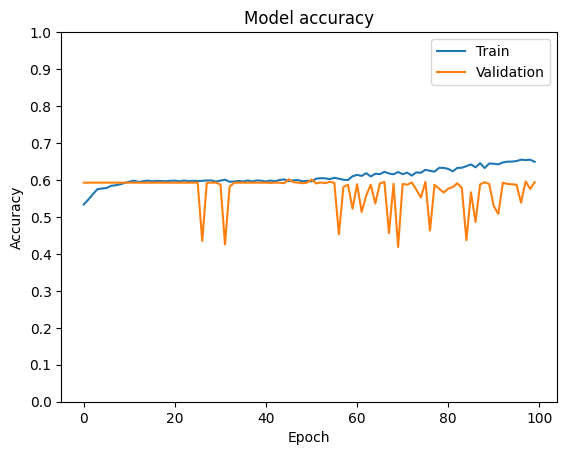

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_lstm.history['accuracy'])
plt.plot(history_lstm.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

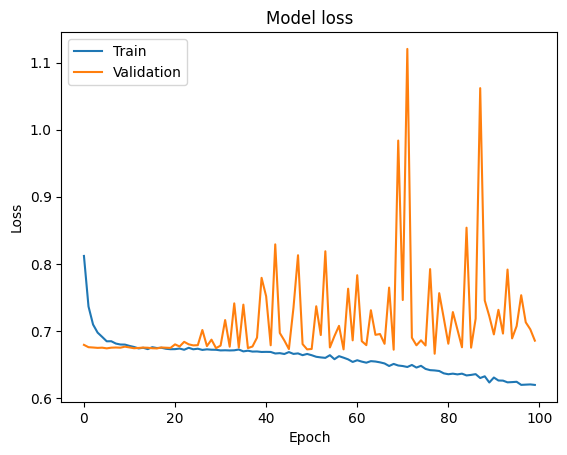

In [ ]:
# Plot training & validation loss values
plt.plot(history_lstm.history['loss'])
plt.plot(history_lstm.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
#Predict train
y_predict_lstm_train = np.round(model_lstm.predict(X_train_lstm))
cm_lstm_train = confusion_matrix(Y_train, np.round(y_predict_lstm_train))
cm_lstm_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 53s 294ms/step


array([[ 114, 2165],
       [  29, 3365]])

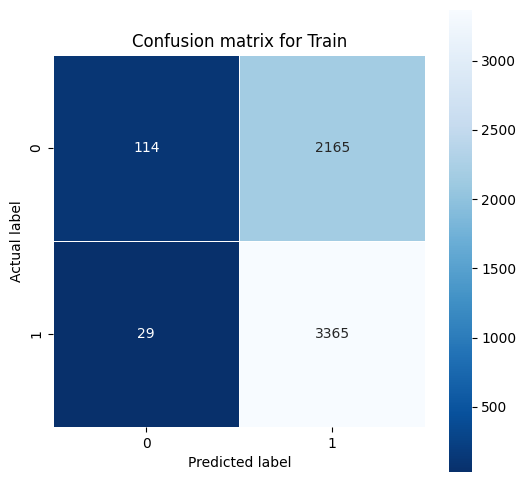

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_lstm_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for Train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_lstm_train = classification_report(y_predict_lstm_train, Y_train)
print("LSTM Train Report:\n ",  report_lstm_train)

LSTM Train Report:
                precision    recall  f1-score   support

         0.0       0.05      0.80      0.09       143
         1.0       0.99      0.61      0.75      5530

    accuracy                           0.61      5673
   macro avg       0.52      0.70      0.42      5673
weighted avg       0.97      0.61      0.74      5673



In [ ]:
#Predict train
y_predict_lstm_test = np.round(model_lstm.predict(X_test_lstm))
cm_lstm_test = confusion_matrix(Y_test, np.round(y_predict_lstm_test))
cm_lstm_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 13s 284ms/step


array([[ 17, 561],
       [ 15, 826]])

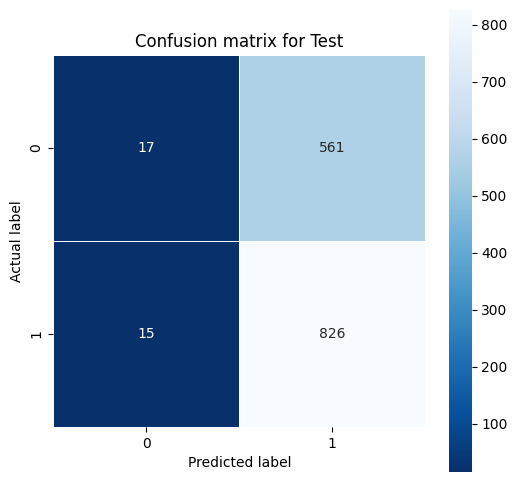

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_lstm_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for Test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_lstm_test = classification_report(y_predict_lstm_test, Y_test)
print("LSTM Test Report:\n ",  report_lstm_test)

LSTM Test Report:
                precision    recall  f1-score   support

         0.0       0.03      0.53      0.06        32
         1.0       0.98      0.60      0.74      1387

    accuracy                           0.59      1419
   macro avg       0.51      0.56      0.40      1419
weighted avg       0.96      0.59      0.73      1419



In [ ]:
model_lstm.save('/content/drive/MyDrive/LSTM.keras')

##GRU

In [ ]:
X_train_gru = X_train.reshape(-1, 576, 70)
X_test_gru = X_test.reshape(-1, 576, 70)

In [ ]:
model_gru = Sequential()

model_gru.add(GRU(units=256, input_shape=(576, 70)))
model_gru.add(BatchNormalization())
model_gru.add(Dropout(0.5))

model_gru.add(Dense(100, activation='elu'))
model_gru.add(Dropout(0.3))

model_gru.add(Dense(50, activation = 'elu'))
model_gru.add(Dropout(0.3))

model_gru.add(Dense(1, activation='sigmoid'))

In [ ]:
model_gru.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_gru.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 256)                 │         251,904 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 100)                 │          25,700 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_16 (Dropout)                 │ (None, 100)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_17 (Dropout)                 │ (None, 50)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 283,729 (1.08 MB)

 Trainable params: 283,217 (1.08 MB)

 Non-trainable params: 512 (2.00 KB)

In [ ]:
history_gru = model_gru.fit(X_train_gru, Y_train, epochs= 100, batch_size= 32, validation_data=(X_test_gru, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 133s 736ms/step - accuracy: 0.5146 - loss: 0.7970 - val_accuracy: 0.5927 - val_loss: 0.6762
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 123s 694ms/step - accuracy: 0.5588 - loss: 0.7151 - val_accuracy: 0.5877 - val_loss: 0.6789
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 129s 723ms/step - accuracy: 0.5503 - loss: 0.7029 - val_accuracy: 0.5835 - val_loss: 0.6743
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 124s 697ms/step - accuracy: 0.5686 - loss: 0.6910 - val_accuracy: 0.5920 - val_loss: 0.6736
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 126s 710ms/step - accuracy: 0.5760 - loss: 0.6846 - val_accuracy: 0.5884 - val_loss: 0.6758
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 125s 705ms/step - accuracy: 0.5792 - loss: 0.6817 - val_accuracy: 0.5884 - val_loss: 0.6849
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 122s 684ms/step - accuracy: 0.5829 - loss: 0.6756 - val_accuracy: 0.5948 - val_loss: 0.6687
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 124s 695ms/step - accuracy: 

In [ ]:
model_gru.evaluate(X_test_gru, Y_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 12s 276ms/step - accuracy: 0.9494 - loss: 0.3351


[0.3133266270160675, 0.9443269968032837]

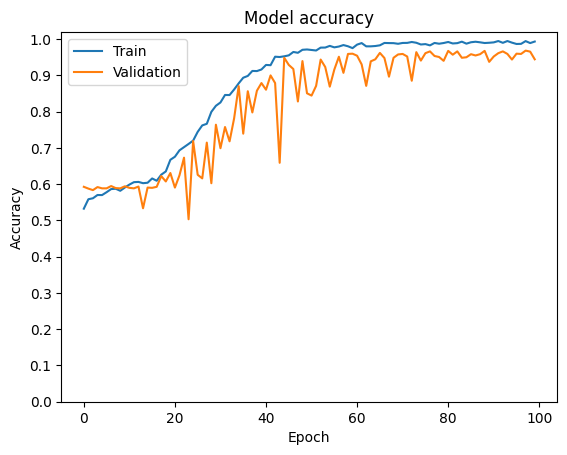

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_gru.history['accuracy'])
plt.plot(history_gru.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

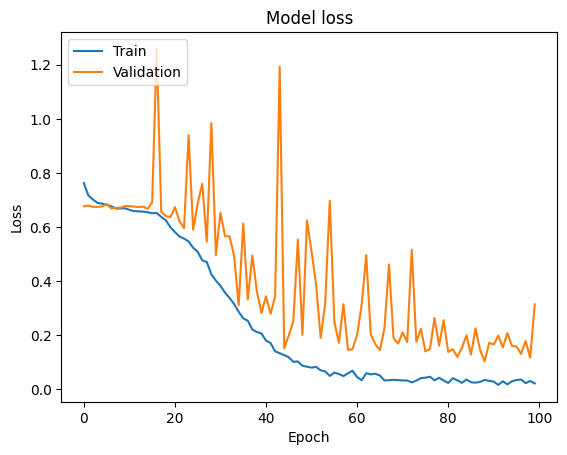

In [ ]:
# Plot training & validation loss values
plt.plot(history_gru.history['loss'])
plt.plot(history_gru.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
#Predict train
y_predict_gru_train = np.round(model_gru.predict(X_train_gru))
cm_gru_train = confusion_matrix(Y_train, np.round(y_predict_gru_train))
cm_gru_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 50s 277ms/step


array([[2244,   35],
       [   0, 3394]])

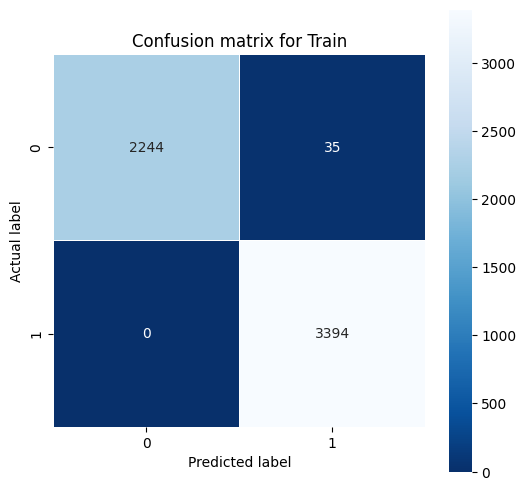

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_gru_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for Train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_gru_train = classification_report(y_predict_gru_train, Y_train)
print("GRU Train Report:\n ",  report_gru_train)

GRU Train Report:
                precision    recall  f1-score   support

         0.0       0.98      1.00      0.99      2244
         1.0       1.00      0.99      0.99      3429

    accuracy                           0.99      5673
   macro avg       0.99      0.99      0.99      5673
weighted avg       0.99      0.99      0.99      5673



In [ ]:
#Predict train
y_predict_gru_test = np.round(model_gru.predict(X_test_gru))
cm_gru_test = confusion_matrix(Y_test, np.round(y_predict_gru_test))
cm_gru_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 12s 258ms/step


array([[510,  68],
       [ 11, 830]])

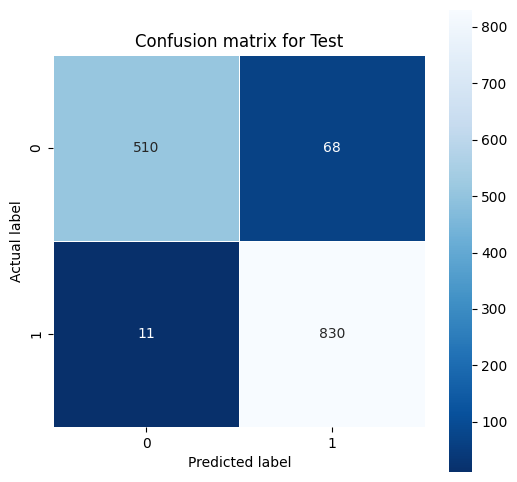

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_gru_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for Test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_gru_test = classification_report(y_predict_gru_test, Y_test)
print("GRU Test Report:\n ",  report_gru_test)

GRU Test Report:
                precision    recall  f1-score   support

         0.0       0.88      0.98      0.93       521
         1.0       0.99      0.92      0.95       898

    accuracy                           0.94      1419
   macro avg       0.93      0.95      0.94      1419
weighted avg       0.95      0.94      0.94      1419



In [ ]:
model_gru.save('/content/drive/MyDrive/GRU.keras')

### CNN_LSTM

In [ ]:
X_train_cnn_lstm = X_train.reshape(-1, 576, 70)
X_test_cnn_lstm = X_test.reshape(-1,576, 70)

In [ ]:
model = Sequential()


model.add(Conv1D(filters=64, kernel_size=5, activation='elu', input_shape=(576, 70)))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))


model.add(Conv1D(filters=128, kernel_size=3, activation='elu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.4))


model.add(Conv1D(filters=256, kernel_size=3, activation='elu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.4))


model.add(LSTM(units=128, return_sequences=True))
model.add(Dropout(0.3))
model.add(LSTM(units=128, return_sequences=False))
model.add(Dropout(0.3))


model.add(Flatten())

model.add(Dense(128, activation='elu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='sigmoid'))

In [ ]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_9 (Conv1D)                    │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_9 (MaxPooling1D)       │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_10 (Conv1D)                   │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_10 (MaxPooling1D)      │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_11 (Conv1D)                   │ (None, 140, 256)            │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_14               │ (None, 140, 256)            │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_11 (MaxPooling1D)      │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 70, 128)             │         197,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_21 (Dropout)                 │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_22 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_23 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 1)                   │             1

 Total params: 492,865 (1.88 MB)

 Trainable params: 491,969 (1.88 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
history_cl = model.fit(X_train_cnn_lstm, Y_train, epochs=100, batch_size=32, validation_data=(X_test_cnn_lstm, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 44s 218ms/step - accuracy: 0.5586 - loss: 0.6896 - val_accuracy: 0.4531 - val_loss: 0.7036
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 39s 219ms/step - accuracy: 0.6081 - loss: 0.6602 - val_accuracy: 0.5884 - val_loss: 0.6956
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 38s 213ms/step - accuracy: 0.6469 - loss: 0.6324 - val_accuracy: 0.6307 - val_loss: 0.6445
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 38s 213ms/step - accuracy: 0.6734 - loss: 0.6157 - val_accuracy: 0.6124 - val_loss: 0.6357
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 36s 201ms/step - accuracy: 0.6791 - loss: 0.5932 - val_accuracy: 0.6927 - val_loss: 0.5769
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 39s 217ms/step - accuracy: 0.6976 - loss: 0.5715 - val_accuracy: 0.7111 - val_loss: 0.5611
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 40s 227ms/step - accuracy: 0.7485 - loss: 0.5178 - val_accuracy: 0.7498 - val_loss: 0.5067
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 40s 223ms/step - accuracy: 0.7672 -

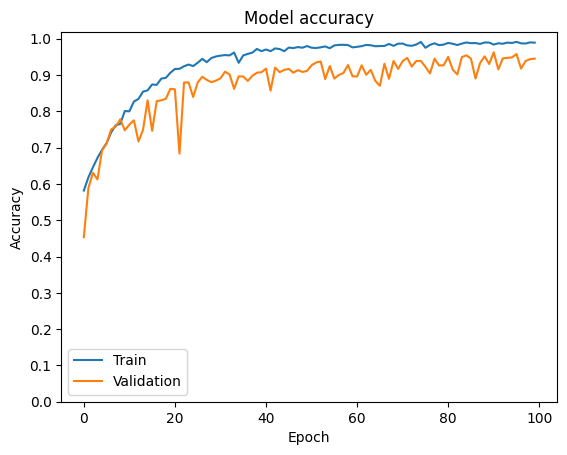

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_cl.history['accuracy'])
plt.plot(history_cl.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

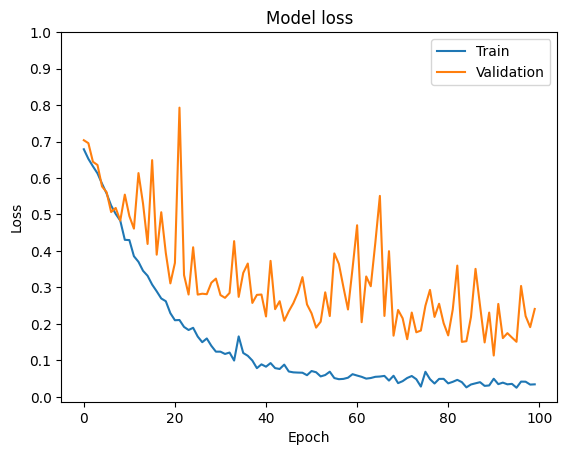

In [ ]:
# Plot training & validation loss values
plt.plot(history_cl.history['loss'])
plt.plot(history_cl.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

In [ ]:
#Predict train
y_predict_cl_train = np.round(model.predict(X_train_cnn_lstm))
cm_cl_train = confusion_matrix(Y_train, np.round(y_predict_cl_train))
cm_cl_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 12s 65ms/step


array([[2250,   29],
       [   3, 3391]])

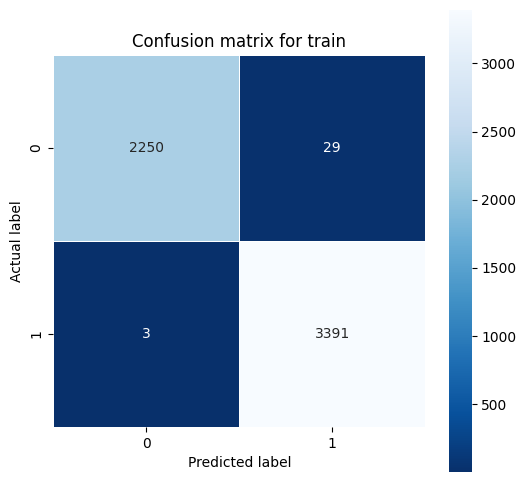

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cl_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cnn_lstm_train = classification_report(y_predict_cl_train, Y_train)
print("Report for Train: \n", report_cnn_lstm_train)

Report for Train: 
               precision    recall  f1-score   support

         0.0       0.99      1.00      0.99      2253
         1.0       1.00      0.99      1.00      3420

    accuracy                           0.99      5673
   macro avg       0.99      1.00      0.99      5673
weighted avg       0.99      0.99      0.99      5673



In [ ]:
#Predict test
y_predict_cl_test = np.round(model.predict(X_test_cnn_lstm))
cm_cl_test = confusion_matrix(Y_test, np.round(y_predict_cl_test))
cm_cl_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step


array([[509,  69],
       [  9, 832]])

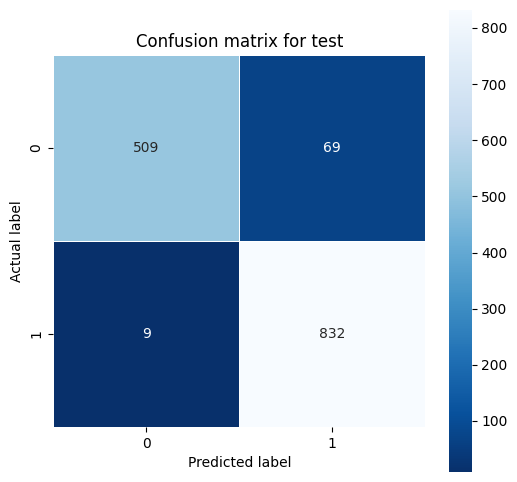

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cl_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cnn_lstm = classification_report(y_predict_cl_test, Y_test)
print("Report for Test:\n ", report_cnn_lstm)

Report for Test:
                precision    recall  f1-score   support

         0.0       0.88      0.98      0.93       518
         1.0       0.99      0.92      0.96       901

    accuracy                           0.95      1419
   macro avg       0.93      0.95      0.94      1419
weighted avg       0.95      0.95      0.95      1419



In [ ]:
model.save("/content/drive/MyDrive/cnn_lstm.keras")

### CNN_SVM

In [ ]:
X_train_cs = X_train.reshape(-1, 576, 70)
X_test_cs = X_test.reshape(-1, 576, 70)

In [ ]:
model_cs = Sequential()


model_cs.add(Conv1D(filters=64, kernel_size=5, activation='elu', input_shape=(576, 70)))
model_cs.add(BatchNormalization())
model_cs.add(MaxPooling1D(pool_size=2))
model_cs.add(Dropout(0.3))


model_cs.add(Conv1D(filters=128, kernel_size=3, activation='elu'))
model_cs.add(BatchNormalization())
model_cs.add(MaxPooling1D(pool_size=2))
model_cs.add(Dropout(0.4))

model_cs.add(Flatten())

feature = Model(inputs=model_cs.inputs, outputs=model_cs.layers[-1].output)

In [ ]:
X_train_f = feature.predict(X_train_cs)
X_test_f = feature.predict(X_test_cs)

178/178 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


In [ ]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train_f)
X_test_s = sc.transform(X_test_f)

In [ ]:
pca = PCA(n_components=0.85)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

In [ ]:
SVM = make_pipeline(StandardScaler(), SVC(kernel='linear'))

In [ ]:
SVM.fit(X_train_pca, Y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(kernel='linear'))])

In [ ]:
#predict test
y_pred_cs_test = SVM.predict(X_test_pca)
accuracy = accuracy_score(Y_test, y_pred_cs_test)
print("CNN_SVM Test Accuracy: ",accuracy)

CNN_SVM Test Accuracy:  0.6307258632840028


In [ ]:
cm_cs = confusion_matrix(Y_test, y_pred_cs_test)
print(cm_cs)

[[252 326]
 [198 643]]


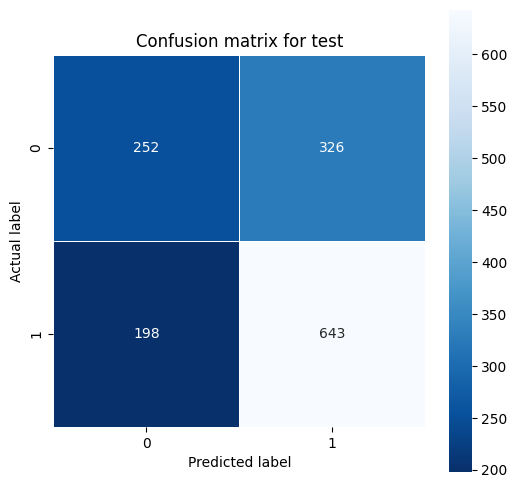

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cs, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cs_test = classification_report(Y_test, y_pred_cs_test)
print("Report for Test :\n", report_cs_test)

Report for Test :
               precision    recall  f1-score   support

         0.0       0.56      0.44      0.49       578
         1.0       0.66      0.76      0.71       841

    accuracy                           0.63      1419
   macro avg       0.61      0.60      0.60      1419
weighted avg       0.62      0.63      0.62      1419



In [ ]:
#predict train
y_pred_svm_train = SVM.predict(X_train_pca)
accuracy_train = accuracy_score(Y_train, y_pred_svm_train)
print("CNN_SVM  Train Accuracy:", accuracy_train)

CNN_SVM  Train Accuracy: 0.6998060990657501


In [ ]:
cm_cs_train = confusion_matrix(Y_train, y_pred_svm_train)
print(cm_cs_train)

[[1140 1139]
 [ 564 2830]]


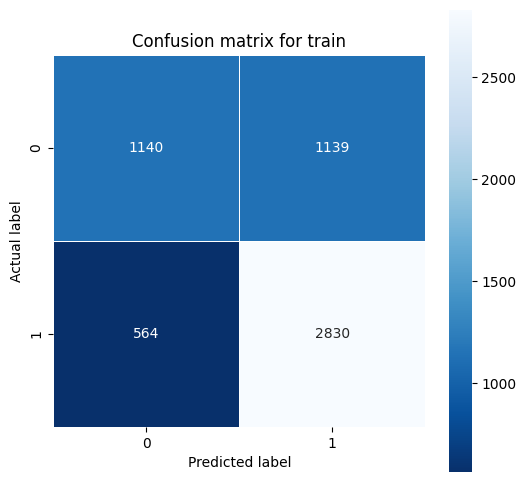

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cs_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cs_train = classification_report(Y_train, y_pred_svm_train)
print("Report for Train :\n", report_cs_train)

Report for Train :
               precision    recall  f1-score   support

         0.0       0.67      0.50      0.57      2279
         1.0       0.71      0.83      0.77      3394

    accuracy                           0.70      5673
   macro avg       0.69      0.67      0.67      5673
weighted avg       0.70      0.70      0.69      5673



In [ ]:
# Save the CNN model
model_cs.save('cnn_svm.keras')

# Save the SVM classifier
joblib.dump(SVM, 'svm.pkl')

['svm.pkl']

### CNN_RNN

In [ ]:
model_cr = Sequential()

model_cr.add(Conv1D(filters=64, kernel_size=5, activation='elu', input_shape=(576, 70)))
model_cr.add(BatchNormalization())
model_cr.add(MaxPooling1D(pool_size=2))
model_cr.add(Dropout(0.3))

model_cr.add(Conv1D(filters=128, kernel_size=3, activation='elu'))
model_cr.add(BatchNormalization())
model_cr.add(MaxPooling1D(pool_size=2))
model_cr.add(Dropout(0.4))

model_cr.add(Conv1D(filters=128, kernel_size=3, activation='elu'))
model_cr.add(BatchNormalization())
model_cr.add(MaxPooling1D(pool_size=2))
model_cr.add(Dropout(0.4))

model_cr.add(SimpleRNN(units=128, return_sequences=True))
model_cr.add(Dropout(0.3))

model_cr.add(SimpleRNN(units=128, return_sequences=False))
model_cr.add(Dropout(0.3))

model_cr.add(Flatten())


model_cr.add(Dense(128, activation='elu'))
model_cr.add(Dropout(0.3))

model_cr.add(Dense(1, activation='sigmoid'))

In [ ]:
model_cr.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_cr.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_14 (Conv1D)                   │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_17               │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_14 (MaxPooling1D)      │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_26 (Dropout)                 │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_15 (Conv1D)                   │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_18               │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_15 (MaxPooling1D)      │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_27 (Dropout)                 │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_16 (Conv1D)                   │ (None, 140, 128)            │          49,280 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_19               │ (None, 140, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_16 (MaxPooling1D)      │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_28 (Dropout)                 │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn (SimpleRNN)               │ (None, 70, 128)             │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_29 (Dropout)                 │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_1 (SimpleRNN)             │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_30 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_31 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 1)                   │             1

 Total params: 180,161 (703.75 KB)

 Trainable params: 179,521 (701.25 KB)

 Non-trainable params: 640 (2.50 KB)

In [ ]:
history_cr = model_cr.fit(X_train_cnn_lstm, Y_train, epochs=100, batch_size= 32, validation_data=(X_test_cnn_lstm, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 24s 103ms/step - accuracy: 0.5289 - loss: 0.7637 - val_accuracy: 0.4827 - val_loss: 0.7308
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 18s 99ms/step - accuracy: 0.5466 - loss: 0.7174 - val_accuracy: 0.5631 - val_loss: 0.6811
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 18s 98ms/step - accuracy: 0.5564 - loss: 0.7097 - val_accuracy: 0.5377 - val_loss: 0.6913
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 20s 111ms/step - accuracy: 0.5766 - loss: 0.6841 - val_accuracy: 0.5955 - val_loss: 0.6754
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 19s 105ms/step - accuracy: 0.5822 - loss: 0.6886 - val_accuracy: 0.5574 - val_loss: 0.6855
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 18s 99ms/step - accuracy: 0.5910 - loss: 0.6726 - val_accuracy: 0.5899 - val_loss: 0.6727
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 17s 96ms/step - accuracy: 0.5995 - loss: 0.6706 - val_accuracy: 0.5920 - val_loss: 0.6606
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 17s 94ms/step - accuracy: 0.6209 - loss

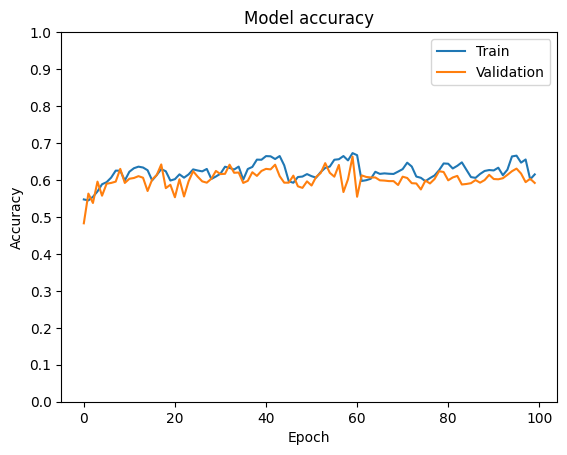

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_cr.history['accuracy'])
plt.plot(history_cr.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

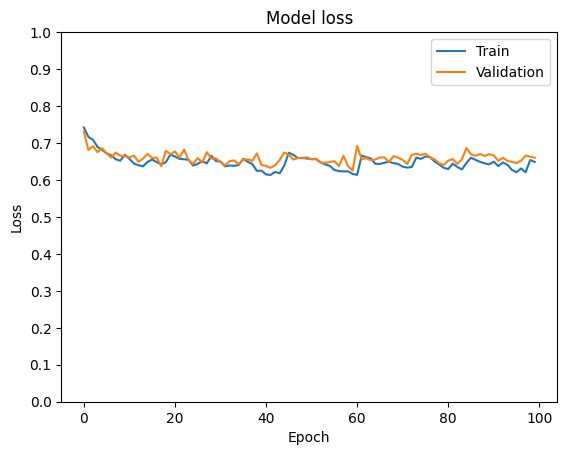

In [ ]:
# Plot training & validation loss values
plt.plot(history_cr.history['loss'])
plt.plot(history_cr.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

In [ ]:
#Predict train
y_predict_cr_train = np.round(model_cr.predict(X_train_cnn_lstm))
cm_cr_train = confusion_matrix(Y_train, np.round(y_predict_cr_train))
cm_cr_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step


array([[ 473, 1806],
       [ 321, 3073]])

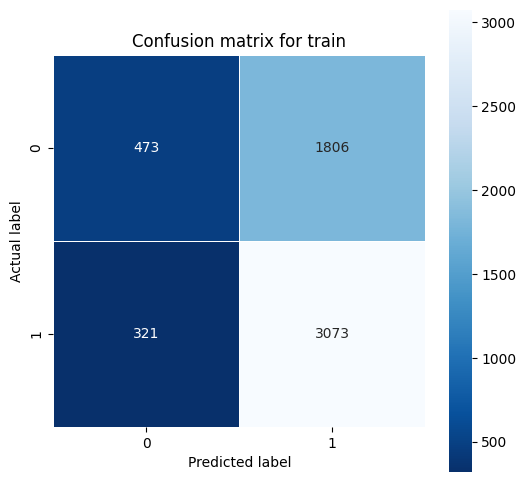

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cr_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_crt = classification_report(y_predict_cr_train, Y_train)
print("Report for Train:\n ", report_crt)

Report for Train:
                precision    recall  f1-score   support

         0.0       0.21      0.60      0.31       794
         1.0       0.91      0.63      0.74      4879

    accuracy                           0.63      5673
   macro avg       0.56      0.61      0.53      5673
weighted avg       0.81      0.63      0.68      5673



In [ ]:
#Predict test
y_predict_cr_test = np.round(model_cr.predict(X_test_cnn_lstm))
cm_cr_test = confusion_matrix(Y_test, np.round(y_predict_cr_test))
cm_cr_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


array([[ 92, 486],
       [ 93, 748]])

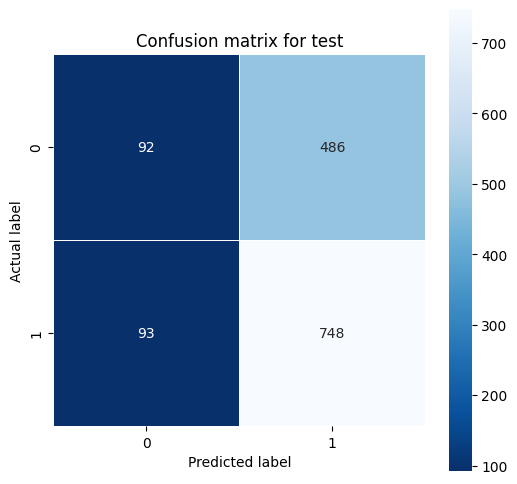

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cr_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cr = classification_report(y_predict_cr_test, Y_test)
print("Report for Test:\n ", report_cr)

Report for Test:
                precision    recall  f1-score   support

         0.0       0.16      0.50      0.24       185
         1.0       0.89      0.61      0.72      1234

    accuracy                           0.59      1419
   macro avg       0.52      0.55      0.48      1419
weighted avg       0.79      0.59      0.66      1419



In [ ]:
model_cr.save("/content/drive/MyDrive/cnn_rnn.keras")

### CNN_GRU

In [ ]:
model_cg = Sequential()


model_cg.add(Conv1D(filters=64, kernel_size=5, activation='elu', input_shape=(576, 70)))
model_cg.add(BatchNormalization())
model_cg.add(MaxPooling1D(pool_size=2))
model_cg.add(Dropout(0.3))


model_cg.add(Conv1D(filters=128, kernel_size=3, activation='elu'))
model_cg.add(BatchNormalization())
model_cg.add(MaxPooling1D(pool_size=2))
model_cg.add(Dropout(0.4))

model_cg.add(Conv1D(filters=256, kernel_size=3, activation='elu', kernel_regularizer=l2(0.01)))
model_cg.add(BatchNormalization())
model_cg.add(MaxPooling1D(pool_size=2))
model_cg.add(Dropout(0.4))

model_cg.add(GRU(units=128, return_sequences=True))
model_cg.add(BatchNormalization())
model_cg.add(Dropout(0.3))


model_cg.add(GRU(units=128, return_sequences=False))
model_cg.add(BatchNormalization())
model_cg.add(Dropout(0.3))

model_cg.add(Flatten())

model_cg.add(Dense(128, activation='elu', kernel_regularizer=l2(0.01)))
model_cg.add(Dropout(0.3))

model_cg.add(Dense(1, activation='sigmoid'))


In [ ]:
model_cg.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_cg.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 140, 256)            │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 140, 256)            │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_2 (MaxPooling1D)       │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru (GRU)                            │ (None, 70, 128)             │         148,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 70, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_1 (GRU)                          │ (None, 128)                 │          99,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 128)                 │              

 Total params: 412,481 (1.57 MB)

 Trainable params: 411,073 (1.57 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [ ]:
history_cg = model_cg.fit(X_train_cnn_lstm, Y_train, epochs=100, batch_size=32, validation_data=(X_test_cnn_lstm, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 30s 139ms/step - accuracy: 0.5335 - loss: 3.4228 - val_accuracy: 0.5899 - val_loss: 2.1863
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 24s 135ms/step - accuracy: 0.5747 - loss: 1.9519 - val_accuracy: 0.4989 - val_loss: 1.3899
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 24s 134ms/step - accuracy: 0.5777 - loss: 1.2440 - val_accuracy: 0.5455 - val_loss: 1.0006
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 25s 139ms/step - accuracy: 0.6011 - loss: 0.9320 - val_accuracy: 0.5899 - val_loss: 0.8390
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 24s 134ms/step - accuracy: 0.6252 - loss: 0.7990 - val_accuracy: 0.5617 - val_loss: 0.8023
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 29s 161ms/step - accuracy: 0.6799 - loss: 0.7307 - val_accuracy: 0.5405 - val_loss: 0.8205
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 24s 136ms/step - accuracy: 0.6811 - loss: 0.6964 - val_accuracy: 0.6906 - val_loss: 0.7009
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 24s 136ms/step - accuracy: 0.7297 -

In [ ]:
model_cg.evaluate(X_test_cnn_lstm, Y_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9584 - loss: 0.2442


[0.23631960153579712, 0.9626497626304626]

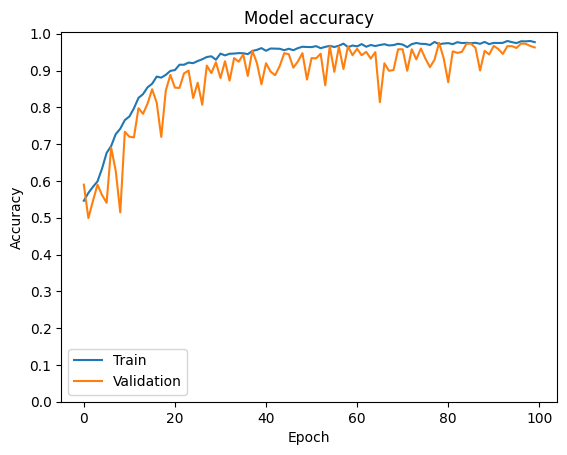

In [ ]:
# Plot training & validation accuracy values
plt.plot(history_cg.history['accuracy'])
plt.plot(history_cg.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

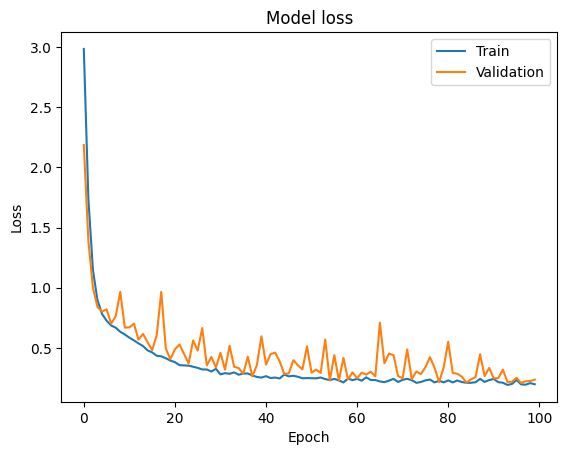

In [ ]:
# Plot training & validation loss values
plt.plot(history_cg.history['loss'])
plt.plot(history_cg.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

In [ ]:
#Predict train
y_predict_cg_train = np.round(model_cg.predict(X_train_cnn_lstm))
cm_cg_train = confusion_matrix(Y_train, np.round(y_predict_cg_train))
cm_cg_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step


array([[2244,   35],
       [  59, 3335]])

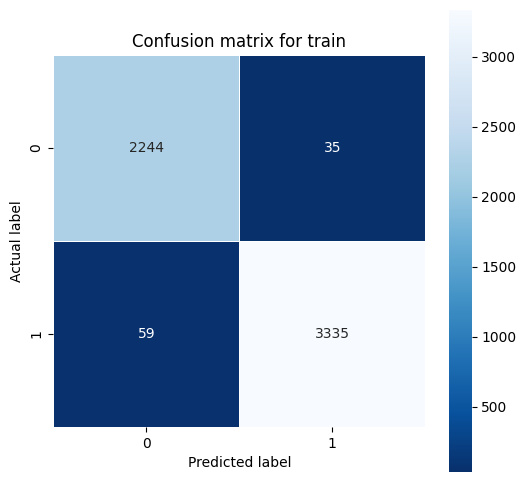

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cg_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cgt = classification_report(y_predict_cg_train, Y_train)
print("Report for Train:\n ", report_cgt)

Report for Train:
                precision    recall  f1-score   support

         0.0       0.98      0.97      0.98      2303
         1.0       0.98      0.99      0.99      3370

    accuracy                           0.98      5673
   macro avg       0.98      0.98      0.98      5673
weighted avg       0.98      0.98      0.98      5673



In [ ]:
#Predict test
y_predict_cg_test = np.round(model_cg.predict(X_test_cnn_lstm))
cm_cg_test = confusion_matrix(Y_test, np.round(y_predict_cg_test))
cm_cg_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step


array([[558,  20],
       [ 33, 808]])

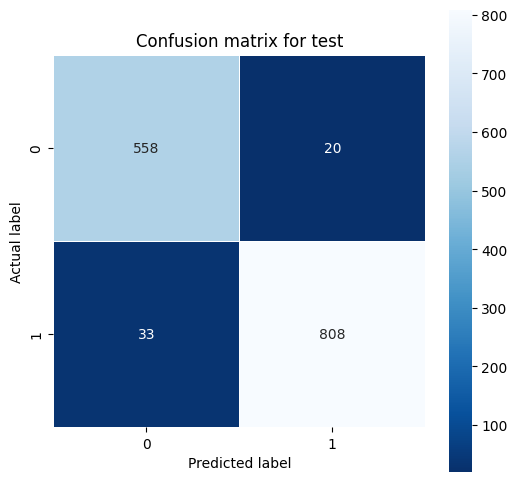

In [ ]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_cg_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [ ]:
report_cg = classification_report(y_predict_cg_test, Y_test)
print("Report for Test:\n ", report_cg)

Report for Test:
                precision    recall  f1-score   support

         0.0       0.97      0.94      0.95       591
         1.0       0.96      0.98      0.97       828

    accuracy                           0.96      1419
   macro avg       0.96      0.96      0.96      1419
weighted avg       0.96      0.96      0.96      1419



In [ ]:
model_cg.save("/content/drive/MyDrive/cnn_gru.keras")

### CNN + LSTM + GRU

In [17]:
model_eeg = Sequential()


model_eeg.add(Conv1D(filters=64, kernel_size=5, activation='elu', input_shape=(576, 70)))
model_eeg.add(BatchNormalization())
model_eeg.add(MaxPooling1D(pool_size=2))
model_eeg.add(Dropout(0.3))


model_eeg.add(Conv1D(filters=128, kernel_size=3, activation='elu'))
model_eeg.add(BatchNormalization())
model_eeg.add(MaxPooling1D(pool_size=2))
model_eeg.add(Dropout(0.4))

model_eeg.add(Conv1D(filters=256, kernel_size=3, activation='elu', kernel_regularizer=l2(0.01)))
model_eeg.add(BatchNormalization())
model_eeg.add(MaxPooling1D(pool_size=2))
model_eeg.add(Dropout(0.4))

model_eeg.add(LSTM(units=128, return_sequences=True))
model_eeg.add(Dropout(0.3))

model_eeg.add(LSTM(units=128, return_sequences=True))
model_eeg.add(Dropout(0.3))


model_eeg.add(GRU(units=128, return_sequences=False))
model_eeg.add(BatchNormalization())
model_eeg.add(Dropout(0.3))

model_eeg.add(Flatten())

model_eeg.add(Dense(128, activation='elu', kernel_regularizer=l2(0.01)))
model_eeg.add(Dropout(0.3))

model_eeg.add(Dense(1, activation='sigmoid'))

In [18]:
model_eeg.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_eeg.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 572, 64)             │          22,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 572, 64)             │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 286, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 284, 128)            │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 284, 128)            │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 142, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 140, 256)            │          98,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 140, 256)            │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_2 (MaxPooling1D)       │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 70, 256)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 70, 128)             │         197,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 70, 128)             │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 70, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru (GRU)                            │ (None, 128)                 │          99,072 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 592,449 (2.26 MB)

 Trainable params: 591,297 (2.26 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [19]:
history_eeg = model_eeg.fit(X_train_1d, Y_train, epochs=100, batch_size=32, validation_data=(X_test_1d, Y_test))

Epoch 1/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.5080 - loss: 3.2642 - val_accuracy: 0.5821 - val_loss: 1.7159
Epoch 2/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.5595 - loss: 1.5285 - val_accuracy: 0.6047 - val_loss: 1.0857
Epoch 3/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.6005 - loss: 1.0445 - val_accuracy: 0.5927 - val_loss: 0.9200
Epoch 4/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.6580 - loss: 0.8405 - val_accuracy: 0.6850 - val_loss: 0.7763
Epoch 5/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.7024 - loss: 0.7335 - val_accuracy: 0.7125 - val_loss: 0.6997
Epoch 6/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.7345 - loss: 0.6496 - val_accuracy: 0.7181 - val_loss: 0.6458
Epoch 7/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.7755 - loss: 0.5710 - val_accuracy: 0.7174 - val_loss: 0.6502
Epoch 8/100
178/178 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.8001 - loss: 0.5275 -

In [20]:
model_eeg.evaluate(X_test_1d, Y_test)

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9723 - loss: 0.1741


[0.178010955452919, 0.9704017043113708]

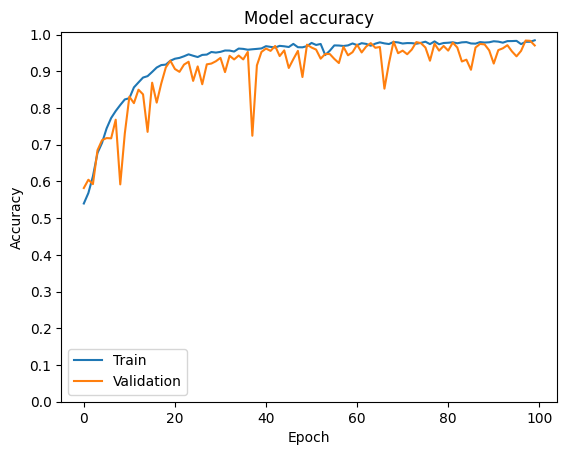

In [21]:
# Plot training & validation accuracy values
plt.plot(history_eeg.history['accuracy'])
plt.plot(history_eeg.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.yticks([0,.10,.20,.30,.40,.50,.60,.70,.80,.90,1])
plt.legend(['Train', 'Validation'])
plt.show()

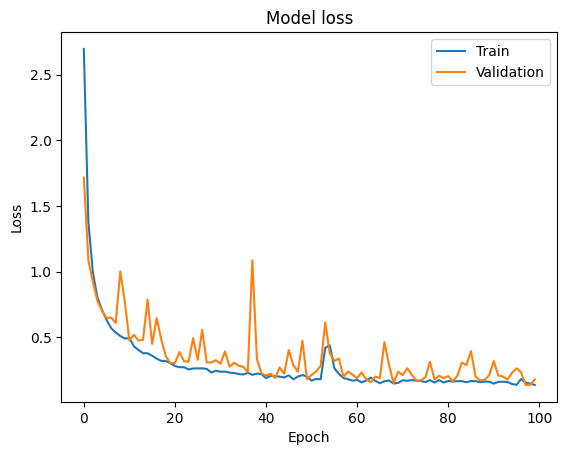

In [22]:
# Plot training & validation loss values
plt.plot(history_eeg.history['loss'])
plt.plot(history_eeg.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])
plt.show()

In [23]:
#Predict train
y_predict_eeg_train = np.round(model_eeg.predict(X_train_1d))
cm_eeg_train = confusion_matrix(Y_train, np.round(y_predict_eeg_train))
cm_eeg_train

178/178 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


array([[2269,   10],
       [  38, 3356]])

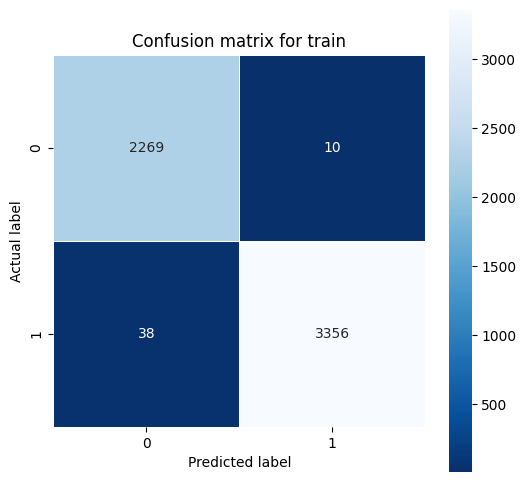

In [24]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_eeg_train, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for train')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [25]:
report_eegt = classification_report(y_predict_eeg_train, Y_train)
print("Report for Train:\n ", report_eegt)

Report for Train:
                precision    recall  f1-score   support

         0.0       1.00      0.98      0.99      2307
         1.0       0.99      1.00      0.99      3366

    accuracy                           0.99      5673
   macro avg       0.99      0.99      0.99      5673
weighted avg       0.99      0.99      0.99      5673



In [26]:
#Predict test
y_predict_eeg_test = np.round(model_eeg.predict(X_test_1d))
cm_eeg_test = confusion_matrix(Y_test, np.round(y_predict_eeg_test))
cm_eeg_test

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


array([[563,  15],
       [ 27, 814]])

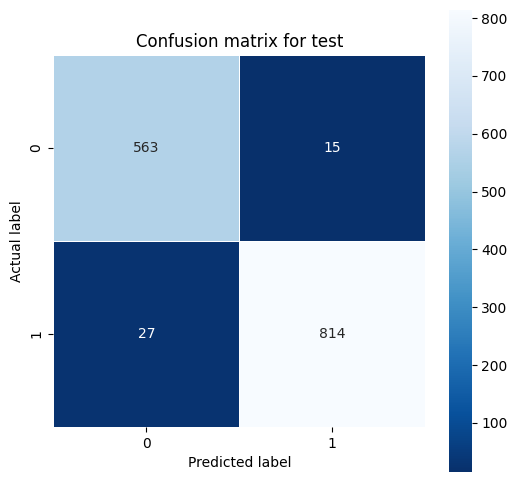

In [27]:
plt.figure(figsize = (6,6))
sns.heatmap(cm_eeg_test, annot=True, fmt='d', linewidth = .5, square = True, cmap = "Blues_r")
plt.title('Confusion matrix for test')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

In [28]:
report_eeg = classification_report(y_predict_eeg_test, Y_test)
print("Report for Test:\n ", report_eeg)

Report for Test:
                precision    recall  f1-score   support

         0.0       0.97      0.95      0.96       590
         1.0       0.97      0.98      0.97       829

    accuracy                           0.97      1419
   macro avg       0.97      0.97      0.97      1419
weighted avg       0.97      0.97      0.97      1419



In [29]:
model_eeg.save("/content/drive/MyDrive/CNN_LSTM_GRU.keras")